# **SMS SPAM DETECTION USING LOGISTIC REGRESSION**

AI101-DS Mini Project

We build a **Logistic Regression** model that reads a text message (SMS) and predicts whether it is

- **Ham (0):** a normal message, or
- **Spam (1):** an unwanted promotional or scam message.

Dataset: SMS Spam Collection, UCI Machine Learning Repository (5,574 messages, CC BY 4.0).
Almeida, T. & Hidalgo, J. (2011). *SMS Spam Collection* [Dataset]. https://doi.org/10.24432/C5CC84

### 1.1 Import Libraries

In [1]:
import warnings
import pandas as pd                      # Read and work with tabular data
import numpy as np                       # Numerical operations
import matplotlib.pyplot as plt          # Graphs
import seaborn as sns                    # Heatmaps

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss
)

warnings.filterwarnings("ignore")        # hides warning messages in the loop later

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.2 Read Dataset

The original file is tab-separated. We converted it into a CSV file with two columns: `label` and `message`.

In [2]:
# https://archive.ics.uci.edu/dataset/228/sms+spam+collection

df = pd.read_csv('data/sms_spam.csv')

print("Dataset shape (rows, columns):", df.shape)

df.head()

Dataset shape (rows, columns): (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 1.3 Understand the Dataset

In [3]:
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nNumber of ham and spam messages:")
print(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing values in each column:
label      0
message    0
dtype: int64

Number of duplicate rows: 403

Number of ham and spam messages:
label
ham     4827
spam     747
Name: count, dtype: int64


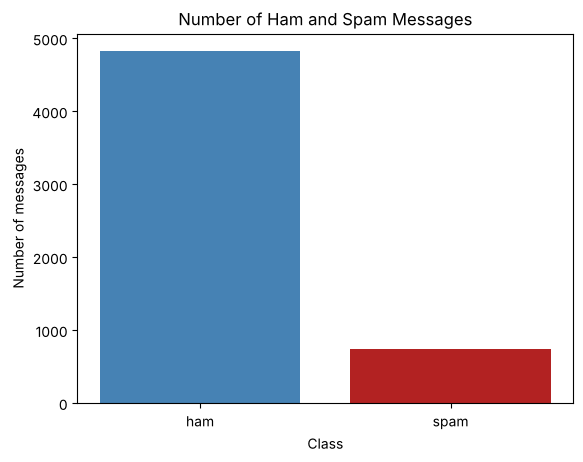

In [4]:
counts = df["label"].value_counts()

plt.bar(counts.index, counts.values, color=["steelblue", "firebrick"])
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.show()

**Note:**

- Only about 13% of the messages are spam, so the classes are **imbalanced**.
- A model that always predicts "ham" would already be about 87% accurate, so accuracy alone is not enough. We will also use precision, recall and F1-score.
- There are 403 duplicate messages. We remove them before splitting, otherwise the same message could be in both the training and testing sets.

### 1.4 Data Preprocessing

1. Remove duplicate rows.
2. Convert the label to numbers: ham = 0, spam = 1.
3. Create four numeric features from the message: message length, number of digits, ratio of capital letters, number of exclamation marks.

In [5]:
# Steps 1 and 2
df = df.drop_duplicates().reset_index(drop=True)
df["spam"] = df["label"].map({"ham": 0, "spam": 1})

print("Rows after removing duplicates:", len(df))
print(df["spam"].value_counts())

Rows after removing duplicates: 5171
spam
0    4518
1     653
Name: count, dtype: int64


In [6]:
# Step 3: numeric features

# length of the message
df["msg_len"] = df["message"].str.len()

# number of digits: count each digit from 0 to 9 and add them up
df["digit_count"] = 0
for d in "0123456789":
    df["digit_count"] = df["digit_count"] + df["message"].str.count(d)

# number of capital letters: count each capital letter from A to Z and add them up
df["capital_count"] = 0
for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
    df["capital_count"] = df["capital_count"] + df["message"].str.count(letter)

# ratio of capital letters = capital letters / total length
df["capital_ratio"] = df["capital_count"] / df["msg_len"]

# number of exclamation marks
df["exclaim_count"] = df["message"].str.count("!")

num_cols = ["msg_len", "digit_count", "capital_ratio", "exclaim_count"]

df[["message"] + num_cols].head()

,message,msg_len,digit_count,capital_ratio,exclaim_count
0,"Go until jurong point, crazy.. Available only ...",111,0,0.027027,0
1,Ok lar... Joking wif u oni...,29,0,0.068966,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,25,0.064516,0
3,U dun say so early hor... U c already then say...,49,0,0.040816,0
4,"Nah I don't think he goes to usf, he lives aro...",61,0,0.032787,0


**Note:**

- `str.count("5")` counts how many times "5" appears in each message. We do this for every digit and add the results to get the total number of digits. The same idea is used for capital letters.
- Spam often has phone numbers, prize codes and exclamation marks, so these features may help.
- We do not clean the text ourselves (lowercase, remove punctuation). `CountVectorizer` in Section 1.8 does it automatically.

### 1.5 Correlation

A correlation value is between -1 and +1. A value close to +1 means that when the feature increases, the chance of spam also increases.

       msg_len  digit_count  capital_ratio  exclaim_count
label                                                    
ham      70.89         0.30           0.06           0.18
spam    137.71        15.49           0.11           0.70


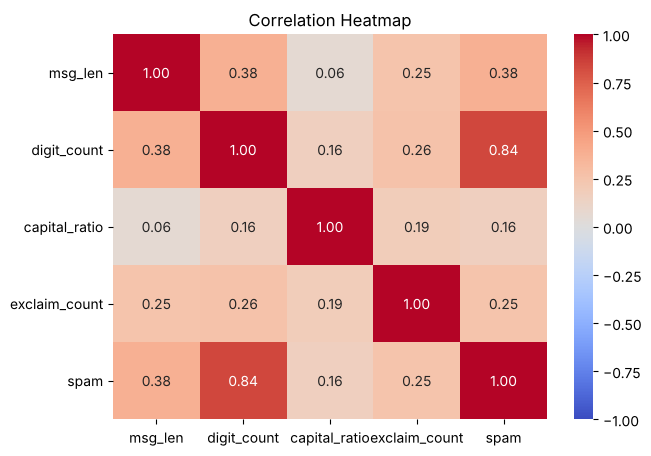

In [7]:
print(df.groupby("label")[num_cols].mean().round(2))

corr = df[num_cols + ["spam"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Note:**

- `digit_count` has the highest correlation with spam (0.84). Spam has about 15 digits on average and ham only about 0.3, because spam contains phone numbers and prize codes.
- `msg_len` (0.38) and `exclaim_count` (0.25) have a smaller positive correlation, and `capital_ratio` (0.16) is weak.
- All four correlations are positive, so we keep all four features.

### 1.6 Features, Target and Train-Test Split

- **X:** the message text and the four numeric features
- **y:** `spam` (0 or 1)

80% of the data is for training and 20% for testing. `stratify=y` keeps the same percentage of spam in both parts.

In [8]:
X = df[["message"] + num_cols]
y = df["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4136, 5)
X_test shape: (1035, 5)


### 1.7 Feature Scaling (Normalization)

The numeric features have very different ranges (`msg_len` can be above 100 while `capital_ratio` is below 1), so we scale them with **StandardScaler**, fitted on the training data only.

In [9]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

print("Scaled numeric training data shape:", X_train_num.shape)

Scaled numeric training data shape: (4136, 4)


### 1.8 Convert Text into Numbers (Bag of Words)

A model cannot read words, so we use **CountVectorizer**.

- It makes the message lowercase and splits it into words.
- Every word in the training messages becomes one column.
- The value in the column is how many times that word appears in the message.
- `min_df=2` ignores words that appear in only one message.

In [10]:
vectorizer = CountVectorizer(min_df=2)

X_train_words = vectorizer.fit_transform(X_train["message"])
X_test_words = vectorizer.transform(X_test["message"])

print("Number of words (columns):", X_train_words.shape[1])

Number of words (columns): 3310


**Note:** `fit_transform()` learns the list of words from the training messages and converts them. `transform()` converts the testing messages using the same list of words, so nothing from the test set is used for training.

### 1.9 Feature Selection (Chi-Square)

We have thousands of word columns, and many are not useful. The **chi-square test** gives every word a score for how strongly it is related to ham or spam. `SelectKBest` keeps only the best `k = 1000` words. We use the training data only.

In [11]:
selector = SelectKBest(chi2, k=1000)

X_train_sel = selector.fit_transform(X_train_words, y_train)
X_test_sel = selector.transform(X_test_words)

print("Words before selection:", X_train_words.shape[1])
print("Words after selection :", X_train_sel.shape[1])

Words before selection: 3310
Words after selection : 1000


### 1.10 Combine the Features

We join the 1000 selected words and the 4 scaled numeric features side by side.

In [12]:
X_train_final = np.hstack([X_train_sel.toarray(), X_train_num])
X_test_final = np.hstack([X_test_sel.toarray(), X_test_num])

print("Final training data shape:", X_train_final.shape)
print("Final testing data shape:", X_test_final.shape)

Final training data shape: (4136, 1004)
Final testing data shape: (1035, 1004)


### 1.11 Training and Testing Functions

- `train_model()` creates a Logistic Regression model and trains it with `fit()`.
- `test_model()` predicts with `predict()` and prints accuracy, precision, recall and F1-score.

`class_weight="balanced"` makes the model pay more attention to the spam class, because spam is the minority class.

In [13]:
def train_model(X_train, y_train, max_iter=100):
    model = LogisticRegression(max_iter=max_iter, class_weight="balanced")
    model.fit(X_train, y_train)
    return model


def test_model(model, X, y_true, name):
    y_pred = model.predict(X)

    print("Results on the", name, "data")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1-score :", round(f1_score(y_true, y_pred), 4))
    print()
    return y_pred

### 1.12 Train the Model

In [14]:
model = train_model(X_train_final, y_train)

print("Logistic Regression model trained successfully!")
print("Iterations used:", model.n_iter_[0])

Logistic Regression model trained successfully!
Iterations used: 28


### 1.13 Training Plot: Loss vs Iterations

While training, the model changes its coefficients step by step to reduce the **log loss** (how wrong its predicted probabilities are). We train a new model for each `max_iter` from 1 to 30 and plot the loss. This is like the loop for K in KNN. The testing loss is only watched for the graph, not used to change the model.

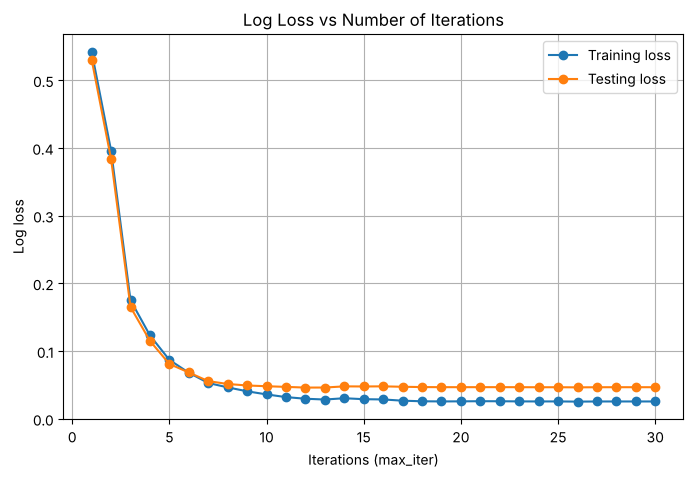

In [15]:
train_loss = []
test_loss = []

for i in range(1, 31):
    temp_model = train_model(X_train_final, y_train, max_iter=i)
    train_loss.append(log_loss(y_train, temp_model.predict_proba(X_train_final)))
    test_loss.append(log_loss(y_test, temp_model.predict_proba(X_test_final)))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 31), train_loss, marker="o", label="Training loss")
plt.plot(range(1, 31), test_loss, marker="o", label="Testing loss")
plt.title("Log Loss vs Number of Iterations")
plt.xlabel("Iterations (max_iter)")
plt.ylabel("Log loss")
plt.legend()
plt.grid(True)
plt.show()

**Note:**

- The loss drops quickly in the first 5 iterations (training loss 0.54 at iteration 1 and 0.09 at iteration 5) and then flattens after about 10 iterations.
- The solver stopped by itself at 28 iterations in Section 1.12, so the model has converged.
- At the end the training loss (0.026) is lower than the testing loss (0.047). The testing loss stays flat after about iteration 10 while the training loss still goes down a little, so there is a small amount of overfitting. Both losses are low.
- `LogisticRegression` uses the lbfgs solver, so the x-axis is solver iterations, not epochs. The idea is the same: the loss goes down as the model learns.